# 04 - How stable are admission lines at the top? Parallel-test simulation

Question: if every student sat a parallel version of the same exams (same ability, new questions of the
same difficulty), how many of the students above a selective program's cutoff would still be above it?

Model (src/simulate.py), per year x subject x exam version:
1. Binomial error model: raw | p ~ Binomial(n_max, p), p = the student's true proportion of points.
2. The distribution of p in the population is estimated from the observed raw-score counts
   (nonparametric maximum likelihood, no shape assumption).
3. For each student, a true p is drawn from its posterior given the observed raw score, then a retest
   raw score is drawn; it is equated with the NAEC equating table and converted to a scaled score with
   that year's scaled-score function (reconstructed from the data).
4. The program's competitive score is recomputed; the top K students are compared with the original top K,
   where K = number of students at/above the program's actual cutoff ("program-level places").

Scenarios:
- error multipliers on the error variance of every subject, same exam version as the student actually took:
  "more error (x1.7)" (open items all-or-nothing, 87/51), "baseline (x1)", "half error (x0.5)",
  "quarter error (x0.25)" (as if the tests had 2x / 4x as many items);
- "realistic: new version + equating error": baseline error, plus the retest is taken on a randomly assigned
  version (the student keeps the same percentile of true ability) and NAEC's equating is re-estimated from a
  resampled score distribution (sampling error of the equating), as happens in a real exam year.
Students whose foreign language is not English keep their foreign-language score (no equating table).
Mathematics, English and Georgian are all re-drawn on every simulated retake.

Uncertainty in the true-score distribution: every prior is refitted to B = 200 multinomially resampled
score distributions (bootstrap); a second pass where retake i uses refit i % B gives the boot_* columns.
Tail sensitivity (MACS): the math prior is replaced by the true-score distributions with the smallest / largest
error variance of the top scorers that still fit the data (95% profile likelihood, simulate.npmle_bound).

In [1]:
from common import *
from load import load_equating, load_rating, load_admissions
from scores import recover_raw, top_linear_g
from simulate import (subject_model, equating_delta, retest_equated, fit_check, refit, npmle_bound,
                      top_functional, loglik, GRID, _lik)

eq = load_equating()
old036 = pd.read_csv(ROOT / "data/processed/admitted_036_all.csv", dtype={"prog_code": str, "exam_id": str})
iset_path = ROOT / "data/processed/admitted_iset_all.csv"
oldiset = pd.read_csv(iset_path, dtype={"prog_code": str, "exam_id": str}) if iset_path.exists() else None

PROGRAMS = [  # (label, year, program code)
    ("MACS", 2024, "03601044"), ("MACS", 2025, "03601054"), ("MACS", 2026, "03601044"),
    ("Free Uni ECE", 2024, "03601054"), ("Free Uni ECE", 2025, "03601034"), ("Free Uni ECE", 2026, "03601054"),
    ("ISET (TSU)", 2025, "00101394"), ("ISET (TSU)", 2026, "00101534"),
]
if oldiset is not None and (oldiset.year == 2024).any():
    PROGRAMS.append(("ISET (TSU)", 2024, oldiset[oldiset.year == 2024].prog_code.mode()[0]))
SCEN = {"more error (x1.7)": (51 / 87, False, False, "npmle"), "baseline (x1)": (1.0, False, False, "npmle"),
        "half error (x0.5)": (2.0, False, False, "npmle"), "quarter error (x0.25)": (4.0, False, False, "npmle"),
        "realistic: new version + equating error": (1.0, True, True, "npmle"),
        "realistic, alternative math tail: less error at the top": (1.0, True, True, "fav"),
        "realistic, alternative math tail: more error at the top": (1.0, True, True, "unf")}
MAIN_SCEN = list(SCEN)[:5]
FULL_SCEN_FOR = {"MACS"}  # other programs: baseline + realistic only
R = 1000  # simulated retakes per scenario
B = 200  # bootstrap refits of every true-score prior; retake i uses refit i % B


def prior_bounds(S, year):
    """Alternative math true-score priors with the smallest / largest error variance of the top scorers that
    still fit the data (profile-likelihood bounds, see simulate.npmle_bound), and their fit at the top."""
    fav, unf, rows = {}, {}, []
    for v, m in S.items():
        if v == "__cache__":
            continue
        c, w, n = m["counts"], m["w"], m["n"]
        h = top_functional(n, w, "error")
        for name, sign, store in [("NPMLE", 0, None), ("less error at the top", 1, fav), ("more error at the top", -1, unf)]:
            wb, drop = (w, 0.0) if sign == 0 else (lambda r: (r[0], r[1]["loglik_drop"]))(npmle_bound(c, w, h, sign))
            if store is not None:
                store[v] = wb
            post = _lik(n)[n - 2:] * wb
            post /= post.sum(axis=1, keepdims=True)
            fitted = c.sum() * (_lik(n) @ wb)
            rows.append({"year": year, "version": v, "prior": name, "loglik_drop": drop,
                         **{f"obs_{x}": c[x] for x in (n - 2, n - 1, n)},
                         **{f"fit_{x}": fitted[x] for x in (n - 2, n - 1, n)},
                         **{f"sem_at_{x}": s for x, s in zip((n - 2, n - 1, n), np.sqrt(post @ (n * GRID * (1 - GRID))))},
                         **{f"true_mean_at_{x}": t for x, t in zip((n - 2, n - 1, n), n * post @ GRID)}})
    return refit(S, w_override=fav), refit(S, w_override=unf), rows


def admits(label, year, code):
    if year <= 2024:
        d = old036 if code.startswith("036") else oldiset
        d = d[(d.year == year) & (d.prog_code == code)]
        return d[d.el1.astype(str).str.contains("მათემ")]
    a = load_admissions(year)
    return a[(a.prog_code == code) & (a.el1_code == "MATH")]


YEAR = {}


def year_data(year):
    if year in YEAR:
        return YEAR[year]
    r = load_rating(year)
    rec = recover_raw(r, eq)
    g = {s: d.groupby("equated").scaled.median() for s, d in rec.dropna(subset=["equated"]).groupby("subject")}
    models, checks, boot = {}, [], {}
    brng = np.random.default_rng(year)
    for s in ["MATH", "ENG", "GEO"]:
        models[s] = subject_model(eq[(eq.year == year) & (eq.subject == s)])
        for v, m in models[s].items():
            checks.append({"year": year, "subject": s, "version": v, **fit_check(m["counts"], m["w"])})
        boot[s] = [refit(models[s], rng=brng) for _ in range(B)]
    fav, unf, bound_rows = prior_bounds(models["MATH"], year)
    wide = r.pivot(index="exam_id", columns="subject", values="scaled")
    fl = wide.reindex(columns=["ENG", "RUS", "GER", "FRE"]).bfill(axis=1).iloc[:, 0]
    pop = pd.DataFrame({"GEO": wide["GEO"], "FL": fl, "MATH": wide["MATH"]}).dropna()
    info = rec.set_index(["exam_id", "subject"])[["raw", "version"]]
    for s in ["MATH", "ENG", "GEO"]:
        sub = info.xs(s, level="subject").reindex(pop.index)
        pop[f"{s}_raw"], pop[f"{s}_ver"] = sub.raw, sub.version
    pop["is_eng"] = wide["ENG"].reindex(pop.index).notna()
    b = top_linear_g(pop.MATH.values, eq[(eq.year == year) & (eq.subject == "MATH")])[1]
    YEAR[year] = (pop, models, g, b, pd.DataFrame(checks), boot, {"fav": fav, "unf": unf}, bound_rows)
    return YEAR[year]


def run(label, year, code, rng, rng_x):
    pop_all, models, g, b, _, boot, bounds, _ = year_data(year)
    a = admits(label, year, code)
    X = a[["geo_sc", "fl_sc", "el1_sc"]].values
    w, *_ = np.linalg.lstsq(X, a.comp.values, rcond=None)
    w = np.round(w, 6)
    assert np.abs(X @ w - a.comp.values).max() < 0.06, (label, year, w)
    cut = a.comp.min()
    pt = w[2] * b  # one raw math point at the top, in competitive-score points
    pop = pop_all.copy()
    pop["comp"] = (w[0] * pop.GEO + w[1] * pop.FL + w[2] * pop.MATH).round(1)
    pop = pop[pop.comp >= cut - 20 * pt].copy()
    K = int((pop.comp >= cut).sum())
    orig_top = (pop.comp >= cut).values
    rows, per = [], []

    def sim(L, switch, eqerr, prior, rng):
        stay = np.zeros(len(pop))
        changed = []
        for i in range(R):
            new = {}
            for s, col in [("MATH", "MATH"), ("ENG", "FL"), ("GEO", "GEO")]:
                sc = pop[col].values.copy()
                ok = pop[f"{s}_raw"].notna().values & pop[f"{s}_ver"].isin(list(models[s])).values
                if s == "ENG":
                    ok &= pop.is_eng.values
                d = equating_delta(models[s], rng) if eqerr else None
                M = {"npmle": models[s], "boot": boot[s][i % B]}.get(prior, bounds.get(prior) if s == "MATH" else models[s])
                e = retest_equated(pop[f"{s}_raw"].values[ok], pop[f"{s}_ver"].values[ok], M, L, switch, d, rng)
                sc[ok] = np.interp(e, g[s].index.values, g[s].values)
                new[col] = sc
            comp = w[0] * new["GEO"] + w[1] * new["FL"] + w[2] * new["MATH"] + rng.random(len(pop)) * 1e-6
            top = np.zeros(len(pop), bool)
            top[np.argsort(-comp)[:K]] = True
            stay += top
            changed.append((orig_top & ~top).sum())
        return np.array(changed), stay / R

    for name, (L, switch, eqerr, prior) in SCEN.items():
        if label not in FULL_SCEN_FOR and name not in ("baseline (x1)", "realistic: new version + equating error"):
            continue
        # main scenarios: point estimates with the fitted prior (rng, as before); the bootstrap pass (rng_x)
        # adds the uncertainty of the estimated true-score distribution to the 90% range
        changed, p_top = sim(L, switch, eqerr, prior, rng if prior == "npmle" else rng_x)
        cb = sim(L, switch, eqerr, "boot", rng_x)[0] if prior == "npmle" else changed
        rows.append({"program": label, "year": year, "scenario": name, "weights": "/".join(f"{x:g}" for x in w),
                     "admitted_math_route": len(a), "cutoff": cut, "K_places": K, "one_math_question": pt,
                     "mean_places_changing_hands": changed.mean(), "pct_places_changing_hands": 100 * changed.mean() / K,
                     "p05": np.percentile(changed, 5), "p95": np.percentile(changed, 95),
                     "boot_mean": cb.mean(), "boot_p05": np.percentile(cb, 5), "boot_p95": np.percentile(cb, 95),
                     "n_students_simulated": len(pop),
                     "max_p_top_bottom_decile": p_top[pop.comp.values <= np.percentile(pop.comp, 10)].max()})
        d = pop[["comp", "MATH_raw"]].copy()
        d["orig_top"], d["p_top"], d["program"], d["year"], d["scenario"] = orig_top, p_top, label, year, name
        d["dist_q"] = (d.comp - cut) / pt
        per.append(d)
    return rows, per

In [2]:
rng = np.random.default_rng(2026)
rng_x = np.random.default_rng(7)  # bootstrap and tail passes; keeps rng identical to the main runs
results, per_student = [], []
for label, year, code in PROGRAMS:
    rws, per = run(label, year, code, rng, rng_x)
    results += rws
    per_student += per
res = pd.DataFrame(results)
res.to_csv(OUT / "t04_stability_summary.csv", index=False)
ps = pd.concat(per_student)
fits = pd.concat([YEAR[y][4] for y in sorted(YEAR)])
fits.to_csv(OUT / "t04_npmle_fit_checks.csv", index=False)
tail = pd.DataFrame([r for y in sorted(YEAR) for r in YEAR[y][7]])
tail.to_csv(OUT / "t04_tail_bounds.csv", index=False)
res[["program", "year", "scenario", "weights", "K_places", "mean_places_changing_hands", "pct_places_changing_hands",
     "p05", "p95", "max_p_top_bottom_decile"]].round(2)

,program,year,scenario,weights,K_places,mean_places_changing_hands,pct_places_changing_hands,p05,p95,max_p_top_bottom_decile
0,MACS,2024,more error (x1.7),1/3/8,196,76.42,38.99,68.0,85.00,0.0
1,MACS,2024,baseline (x1),1/3/8,196,67.43,34.40,60.0,75.00,0.0
2,MACS,2024,half error (x0.5),1/3/8,196,59.80,30.51,53.0,67.00,0.0
3,MACS,2024,quarter error (x0.25),1/3/8,196,55.14,28.13,48.0,62.00,0.0
4,MACS,2024,realistic: new version + equating error,1/3/8,196,69.90,35.66,62.0,78.00,0.0
5,MACS,2024,"realistic, alternative math tail: less error a...",1/3/8,196,67.16,34.27,60.0,75.00,0.0
6,MACS,2024,"realistic, alternative math tail: more error a...",1/3/8,196,80.10,40.87,72.0,89.00,0.0
7,MACS,2025,more error (x1.7),1/1/10,129,56.36,43.69,50.0,63.00,0.0
8,MACS,2025,baseline (x1),1/1/10,129,51.02,39.55,44.0,58.00,0.0
9,MACS,2025,half error (x0.5),1/1/10,129,45.75,35.47,39.0,52.00,0.0


Check: `max_p_top_bottom_decile` ~ 0 means students at the bottom of the simulated window never reach the
top K, so restricting the simulation to the window does not change the result.

## Probability of being above the line on a parallel test, by distance from the cutoff
Distance measured in math questions (raw math points at the top, converted with the program's weight).

In [3]:
bins = [-12, -4, -3, -2, -1, 0, 1, 2, 3, 10]
ps["band"] = pd.cut(ps.dist_q, bins, right=False)
band = (ps.groupby(["program", "year", "scenario", "band"], observed=True)
        .agg(n=("p_top", "size"), mean_p_above_line=("p_top", "mean")).reset_index())
band.to_csv(OUT / "t04_stability_by_distance.csv", index=False)
band[(band.program == "MACS") & band.scenario.isin(["baseline (x1)", "realistic: new version + equating error"])].pivot(
    index="band", columns=["year", "scenario"], values="mean_p_above_line").round(3)

year               2024                                                  2025                                                  2026                                        
scenario  baseline (x1) realistic: new version + equating error baseline (x1) realistic: new version + equating error baseline (x1) realistic: new version + equating error
band                                                                                                                                                                       
[-12, -4)         0.014                                   0.016         0.008                                   0.011         0.007                                   0.009
[-4, -3)          0.087                                   0.092         0.078                                   0.086         0.044                                   0.047
[-3, -2)          0.146                                   0.150         0.142                                   0.152         0.073                                   0.074
[-2, -1)          0.240                                   0.245         0.216                                   0.224         0.130                                   0.130
[-1, 0)           0.353                                   0.357         0.327                                   0.322         0.287                                   0.284
[0, 1)            0.463                                   0.461         0.471                                   0.454         0.571                                   0.561
[1, 2)            0.591                                   0.582         0.699                                   0.662         0.771                                   0.759
[2, 3)            0.754                                   0.736         0.846                                   0.811         0.872                                   0.864
[3, 10)           0.920                                   0.893           NaN                                     NaN           NaN                                     NaN

## Who would replace them? (MACS, expected entrants from below the line, by original math raw score)

In [4]:
ent = (ps[(ps.program == "MACS") & (~ps.orig_top) & ps.scenario.isin(["baseline (x1)", "realistic: new version + equating error"])]
       .groupby(["year", "scenario", "MATH_raw"]).p_top.sum().rename("expected_entrants").reset_index())
ent = ent[ent.expected_entrants > 0.05]
ent.to_csv(OUT / "t04_entrants_by_math_raw.csv", index=False)
ent.pivot(index="MATH_raw", columns=["year", "scenario"], values="expected_entrants").round(2)

year              2024                                                  2025                                                  2026                                        
scenario baseline (x1) realistic: new version + equating error baseline (x1) realistic: new version + equating error baseline (x1) realistic: new version + equating error
MATH_raw                                                                                                                                                                  
33.0               NaN                                    0.05           NaN                                     NaN           NaN                                     NaN
34.0              0.10                                    0.12           NaN                                     NaN           NaN                                     NaN
35.0              0.18                                    0.20           NaN                                     NaN           NaN                                     NaN
36.0              0.37                                    0.40           NaN                                     NaN           NaN                                    0.07
37.0              0.42                                    0.55           NaN                                     NaN           NaN                                    0.16
38.0              0.73                                    0.96          0.05                                    0.08           NaN                                    0.23
39.0              1.30                                    1.46          0.07                                    0.16          0.12                                    0.33
40.0              2.32                                    2.64          0.16                                    0.34          0.23                                    0.50
41.0              2.95                                    3.26          0.26                                    0.46          0.60                                    0.89
42.0              5.38                                    5.70          0.49                                    0.92          1.00                                    1.18
43.0              6.98                                    7.16          1.02                                    1.40          1.82                                    1.95
44.0             11.24                                   11.37          1.81                                    2.20          3.94                                    3.93
45.0             11.40                                   11.77          3.82                                    4.20          5.13                                    5.24
46.0             12.26                                   12.42          6.17                                    6.63          6.52                                    6.63
47.0              8.06                                    8.06         12.76                                   13.18          9.94                                   10.03
48.0              3.58                                    3.62         16.49                                   16.78         12.78                                   12.86
49.0               NaN                                     NaN          7.66                                    7.72         13.30                                   13.44
50.0              0.08                                    0.10          0.23                                    0.25          2.88                                    2.79
51.0               NaN                                     NaN           NaN                                     NaN          0.13                                    0.13

## Figure 6 - Probability of staying above the MACS line on a parallel test (2026)

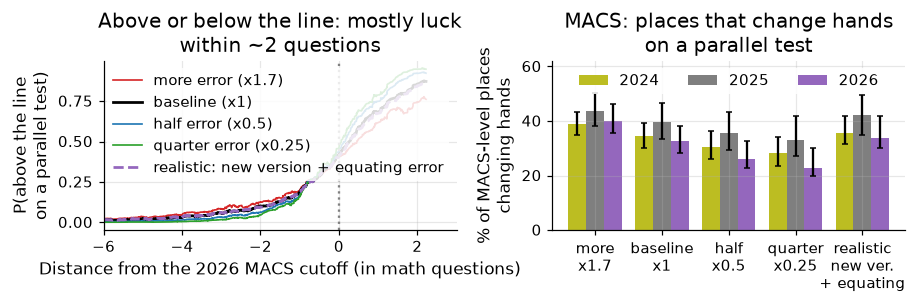

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8.4, 2.9))
ax = axes[0]
colors = dict(zip(MAIN_SCEN, ["tab:red", "black", "tab:blue", "tab:green", "tab:purple"]))
for name in MAIN_SCEN:
    d = ps[(ps.program == "MACS") & (ps.year == 2026) & (ps.scenario == name)].sort_values("comp")
    sm = d.p_top.rolling(25, center=True, min_periods=5).mean()
    ax.plot(d.dist_q, sm, color=colors[name], label=name, lw=1.8 if name.startswith(("baseline", "realistic")) else 1.1,
            ls="--" if name.startswith("realistic") else "-")
ax.axvline(0, color="grey", ls=":")
ax.set_xlim(-6, 3)
ax.set_xlabel("Distance from the 2026 MACS cutoff (in math questions)")
ax.set_ylabel("P(above the line\non a parallel test)")
ax.set_title("Above or below the line: mostly luck\nwithin ~2 questions")
ax.legend(framealpha=0.85, edgecolor="none")
ax = axes[1]
macs = res[res.program == "MACS"]
xs = np.arange(len(MAIN_SCEN))
yrs = sorted(macs.year.unique())
wbar = 0.8 / len(yrs)
for i, (y, c) in enumerate(zip(yrs, ["tab:olive", "tab:gray", "tab:purple"])):
    dd = macs[macs.year == y].set_index("scenario").reindex(MAIN_SCEN)
    ax.bar(xs + (i - (len(yrs) - 1) / 2) * wbar, dd.pct_places_changing_hands, width=wbar, color=c, label=str(y),
           yerr=[100 * (dd.mean_places_changing_hands - dd.boot_p05).clip(lower=0) / dd.K_places, 100 * (dd.boot_p95 - dd.mean_places_changing_hands) / dd.K_places],
           capsize=2)
ax.set_xticks(xs, ["more\nx1.7", "baseline\nx1", "half\nx0.5", "quarter\nx0.25", "realistic\nnew ver.\n+ equating"])
ax.set_ylabel("% of MACS-level places\nchanging hands")
ax.set_title("MACS: places that change hands\non a parallel test")
ax.set_ylim(0, 62)
ax.legend(ncol=3, loc="upper center", framealpha=0.85, edgecolor="none")
fig.tight_layout()
savefig(fig, "fig06_stability")

## Figure 8 - Other selective math programs

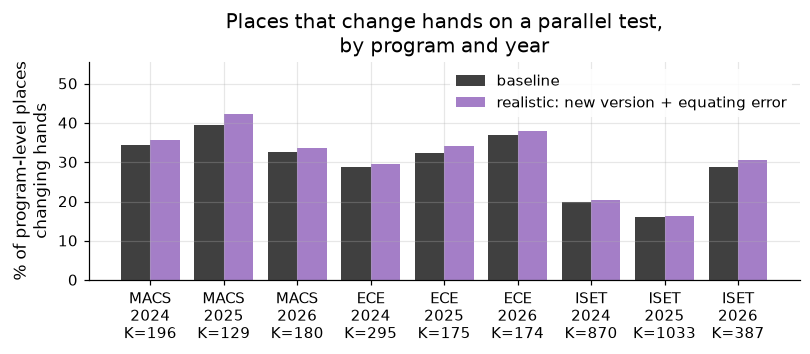

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.35))
progs = [p for p in ["MACS", "Free Uni ECE", "ISET (TSU)"] if p in res.program.unique()]
labels, base, real, lo, hi = [], [], [], [], []
short = {"MACS": "MACS", "Free Uni ECE": "ECE", "ISET (TSU)": "ISET"}
for p in progs:
    for y in sorted(res[res.program == p].year.unique()):
        b_ = res[(res.program == p) & (res.year == y) & (res.scenario == "baseline (x1)")].iloc[0]
        r_ = res[(res.program == p) & (res.year == y) & (res.scenario.str.startswith("realistic"))].iloc[0]
        labels.append(f"{short[p]}\n{y}\nK={b_.K_places}")
        base.append(b_.pct_places_changing_hands)
        real.append(r_.pct_places_changing_hands)
x = np.arange(len(labels))
ax.bar(x - 0.2, base, 0.4, color="black", alpha=0.75, label="baseline")
ax.bar(x + 0.2, real, 0.4, color="tab:purple", alpha=0.85, label="realistic: new version + equating error")
ax.set_xticks(x, labels)
ax.set_ylabel("% of program-level places\nchanging hands")
ax.set_ylim(0, max(base + real) * 1.32)
ax.set_title("Places that change hands on a parallel test,\nby program and year")
ax.legend(framealpha=0.85, edgecolor="none")
fig.tight_layout()
savefig(fig, "fig08_programs_stability")